In [1]:
%pip install requests pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import requests
import pandas as pd
from datetime import datetime

print("Cyber Security Assessment Started")
print("Date:", datetime.now().strftime("%Y-%m-%d %H:%M:%S"))

Cyber Security Assessment Started
Date: 2026-10-25 09:31:38


In [5]:
target_url = "https://example.com"

try:
    response = requests.get(target_url, timeout=15)

    print("Website:", target_url)
    print("Status Code:", response.status_code)
    print("Connection Successful:", response.ok)

except requests.RequestException as error:
    print("Error:", error)

Website: https://example.com
Status Code: 200
Connection Successful: True


In [6]:
security_headers = [
    "Content-Security-Policy",
    "Strict-Transport-Security",
    "X-Content-Type-Options",
    "X-Frame-Options",
    "Referrer-Policy"
]

results = []

for header in security_headers:
    value = response.headers.get(header)

    results.append({
        "Security Header": header,
        "Status": "Present" if value else "Not detected",
        "Value": value or "Missing"
    })

headers_df = pd.DataFrame(results)
display(headers_df)

,Security Header,Status,Value
0,Content-Security-Policy,Not detected,Missing
1,Strict-Transport-Security,Not detected,Missing
2,X-Content-Type-Options,Not detected,Missing
3,X-Frame-Options,Not detected,Missing
4,Referrer-Policy,Not detected,Missing


In [7]:
from urllib.parse import urlparse

protocol = urlparse(target_url).scheme

print("Website:", target_url)
print("Protocol:", protocol.upper())
print("HTTPS Enabled:", protocol == "https")

Website: https://example.com
Protocol: HTTPS
HTTPS Enabled: True


In [8]:
risk_data = [
    {
        "Risk": "Content Security Policy not detected",
        "Severity": "Needs review",
        "Recommendation": "Review CSP configuration"
    },
    {
        "Risk": "HSTS not detected",
        "Severity": "Needs review",
        "Recommendation": "Configure HSTS for HTTPS deployments"
    },
    {
        "Risk": "X-Content-Type-Options not detected",
        "Severity": "Needs review",
        "Recommendation": "Consider setting nosniff"
    },
    {
        "Risk": "X-Frame-Options not detected",
        "Severity": "Needs review",
        "Recommendation": "Review clickjacking protection"
    }
]

risk_df = pd.DataFrame(risk_data)
display(risk_df)

,Risk,Severity,Recommendation
0,Content Security Policy not detected,Needs review,Review CSP configuration
1,HSTS not detected,Needs review,Configure HSTS for HTTPS deployments
2,X-Content-Type-Options not detected,Needs review,Consider setting nosniff
3,X-Frame-Options not detected,Needs review,Review clickjacking protection


In [9]:
headers_df.to_csv("security_headers.csv", index=False)
risk_df.to_csv("security_risks.csv", index=False)

print("CSV files saved successfully!")

CSV files saved successfully!


In [10]:
report = f"""
CYBER SECURITY FUNDAMENTALS & SECURITY ASSESSMENT
=================================================

Date: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}
Target: {target_url}
HTTP Status: {response.status_code}

OBJECTIVE:
Assess basic HTTP security headers and HTTPS usage.

HEADER ANALYSIS:
{headers_df.to_string(index=False)}

RISK CHECKLIST:
{risk_df.to_string(index=False)}

RECOMMENDATIONS:
1. Review security header configuration.
2. Use HTTPS for secure communication.
3. Review clickjacking protection.
4. Review content type and referrer policies.

LIMITATIONS:
This is a basic configuration assessment only.
No penetration testing or exploitation was performed.
Checklist entries require verification before being
reported as actual vulnerabilities.

RESULT:
The preliminary security assessment is complete.
"""

with open("security_assessment_report.txt", "w", encoding="utf-8") as file:
    file.write(report)

print(report)


CYBER SECURITY FUNDAMENTALS & SECURITY ASSESSMENT

Date: 2026-10-25 09:48:49
Target: https://example.com
HTTP Status: 200

OBJECTIVE:
Assess basic HTTP security headers and HTTPS usage.

HEADER ANALYSIS:
          Security Header       Status   Value
  Content-Security-Policy Not detected Missing
Strict-Transport-Security Not detected Missing
   X-Content-Type-Options Not detected Missing
          X-Frame-Options Not detected Missing
          Referrer-Policy Not detected Missing

RISK CHECKLIST:
                                Risk     Severity                       Recommendation
Content Security Policy not detected Needs review             Review CSP configuration
                   HSTS not detected Needs review Configure HSTS for HTTPS deployments
 X-Content-Type-Options not detected Needs review             Consider setting nosniff
        X-Frame-Options not detected Needs review       Review clickjacking protection

RECOMMENDATIONS:
1. Review security header configuration.
2.

In [11]:
import os

for filename in [
    "security_headers.csv",
    "security_risks.csv",
    "security_assessment_report.txt"
]:
    print(filename, "-", "Created" if os.path.exists(filename) else "Not found")

security_headers.csv - Created
security_risks.csv - Created
security_assessment_report.txt - Created


In [12]:
import matplotlib.pyplot as plt

total_headers = len(headers_df)
detected_headers = (headers_df["Status"] == "Present").sum()
missing_headers = total_headers - detected_headers

security_score = (
    detected_headers / total_headers * 100
    if total_headers > 0 else 0
)

print("CYBER SECURITY SCORE")
print("--------------------")
print("Total Headers Checked:", total_headers)
print("Headers Detected:", detected_headers)
print("Headers Not Detected:", missing_headers)
print(f"Header Presence Score: {security_score:.1f}%")

CYBER SECURITY SCORE
--------------------
Total Headers Checked: 5
Headers Detected: 0
Headers Not Detected: 5
Header Presence Score: 0.0%


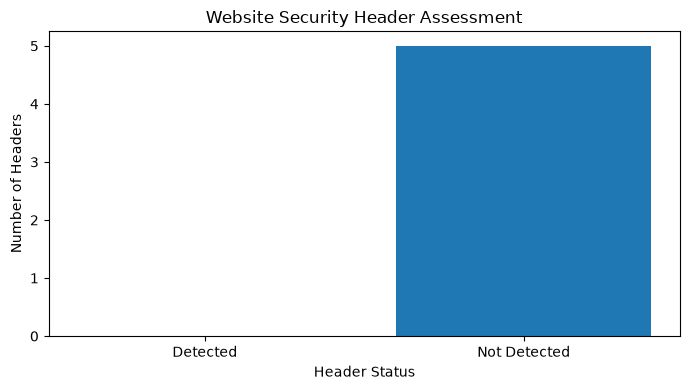

In [13]:
labels = ["Detected", "Not Detected"]
values = [detected_headers, missing_headers]

plt.figure(figsize=(7, 4))
plt.bar(labels, values)
plt.title("Website Security Header Assessment")
plt.xlabel("Header Status")
plt.ylabel("Number of Headers")
plt.yticks(range(0, total_headers + 1))
plt.tight_layout()
plt.show()

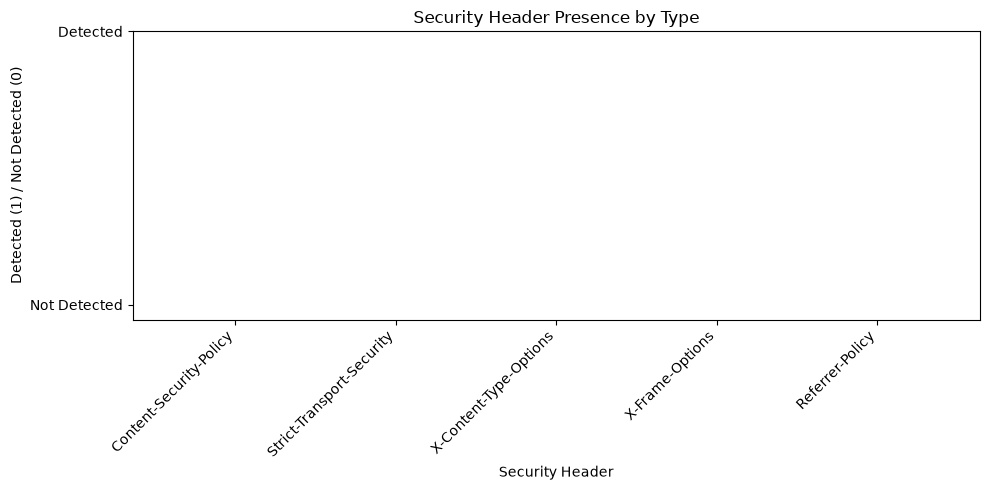

In [14]:
header_counts = headers_df["Status"].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(headers_df["Security Header"], 
        [1 if status == "Present" else 0
         for status in headers_df["Status"]])

plt.title("Security Header Presence by Type")
plt.xlabel("Security Header")
plt.ylabel("Detected (1) / Not Detected (0)")
plt.xticks(rotation=45, ha="right")
plt.yticks([0, 1], ["Not Detected", "Detected"])
plt.tight_layout()
plt.show()

In [15]:
score_df = pd.DataFrame([{
    "Target Website": target_url,
    "Total Headers Checked": total_headers,
    "Headers Detected": detected_headers,
    "Headers Not Detected": missing_headers,
    "Header Presence Score (%)": round(security_score, 1)
}])

score_df.to_csv("security_score.csv", index=False)

display(score_df)
print("Security score saved successfully!")

,Target Website,Total Headers Checked,Headers Detected,Headers Not Detected,Header Presence Score (%)
0,https://example.com,5,0,5,0.0


Security score saved successfully!


In [16]:
with open("security_assessment_report.txt", "a", encoding="utf-8") as file:
    file.write("\n\nSECURITY HEADER SCORE\n")
    file.write("=====================\n")
    file.write(f"Target: {target_url}\n")
    file.write(f"Headers checked: {total_headers}\n")
    file.write(f"Headers detected: {detected_headers}\n")
    file.write(f"Headers not detected: {missing_headers}\n")
    file.write(f"Header presence score: {security_score:.1f}%\n")
    file.write(
        "Note: This score measures header presence only. "
        "It does not represent overall website security.\n"
    )

print("Final report updated successfully!")

Final report updated successfully!
